<a href="https://colab.research.google.com/github/Moon-JB/26-2-DIP-202201276/blob/main/HW02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

과제 1번

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
!pip install nibabel

In [4]:
import nibabel as nib

In [5]:
import os, glob

data_dir = '/content/drive/MyDrive'   # 파일이 하위 폴더에 있다면 그 폴더 경로로 수정

# 드라이브 전체 검색이라 조금 걸릴 수 있습니다. 위치를 알면 생략해도 됩니다.
print(glob.glob(f'{data_dir}/**/volume-covid19-A-0700*', recursive=True))

['/content/drive/MyDrive/volume-covid19-A-0700_day000.nii.gz', '/content/drive/MyDrive/volume-covid19-A-0700_day015.nii.gz']


In [6]:
import os
imgpath = '/content/drive/MyDrive/DIP4E/DIP4E'

In [7]:
from scipy import ndimage
from skimage import io

f1 = io.imread(imgpath + '/galaxy-pair-noisy.tif')
f2 = io.imread(imgpath + '/dentalXray-pepper-noise.tif')

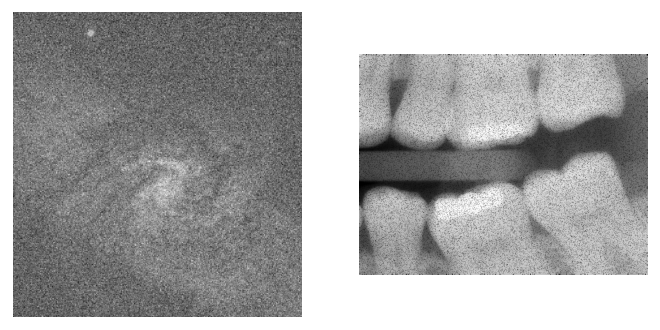

In [8]:
f1 = plt.imread(imgpath+'/galaxy-pair-noisy.tif')
f2 = plt.imread(imgpath+'/dentalXray-pepper-noise.tif')

plt.figure(dpi=128)
plt.subplot(121)
plt.imshow(f1,cmap='gray')
plt.axis('off')
plt.subplot(122)
plt.imshow(f2,cmap='gray')
plt.axis('off')
plt.show()

In [9]:
# 1. Arithmetic Mean Filter

f1_r = ndimage.uniform_filter(f1.astype(float), size=3)
f2_r = ndimage.uniform_filter(f2.astype(float), size=3)

In [10]:
# 2. Median Filter

f1_r = ndimage.median_filter(f1, size=3)
f2_r = ndimage.median_filter(f2, size=3)

In [11]:
# 3. Adaptive Local Noise Reduction

def adaptive_local_noise_reduction(img, size=7):
    img = img.astype(float)

    # 각 픽셀 주변의 국소 평균
    local_mean = ndimage.uniform_filter(img, size=size)

    # 각 픽셀 주변의 국소 제곱 평균
    local_mean_sq = ndimage.uniform_filter(img**2, size=size)

    # 국소 분산 = E[x^2] - E[x]^2
    local_var = np.maximum(local_mean_sq - local_mean**2, 0)

    # 전체 영상에서 잡음 분산 추정
    noise_var = np.mean(local_var)

    # 적응적 잡음 제거
    result = img - noise_var / (local_var + 1e-10) * (img - local_mean)

    return np.clip(result, 0, 255)

f1_r = adaptive_local_noise_reduction(f1)
f2_r = adaptive_local_noise_reduction(f2)

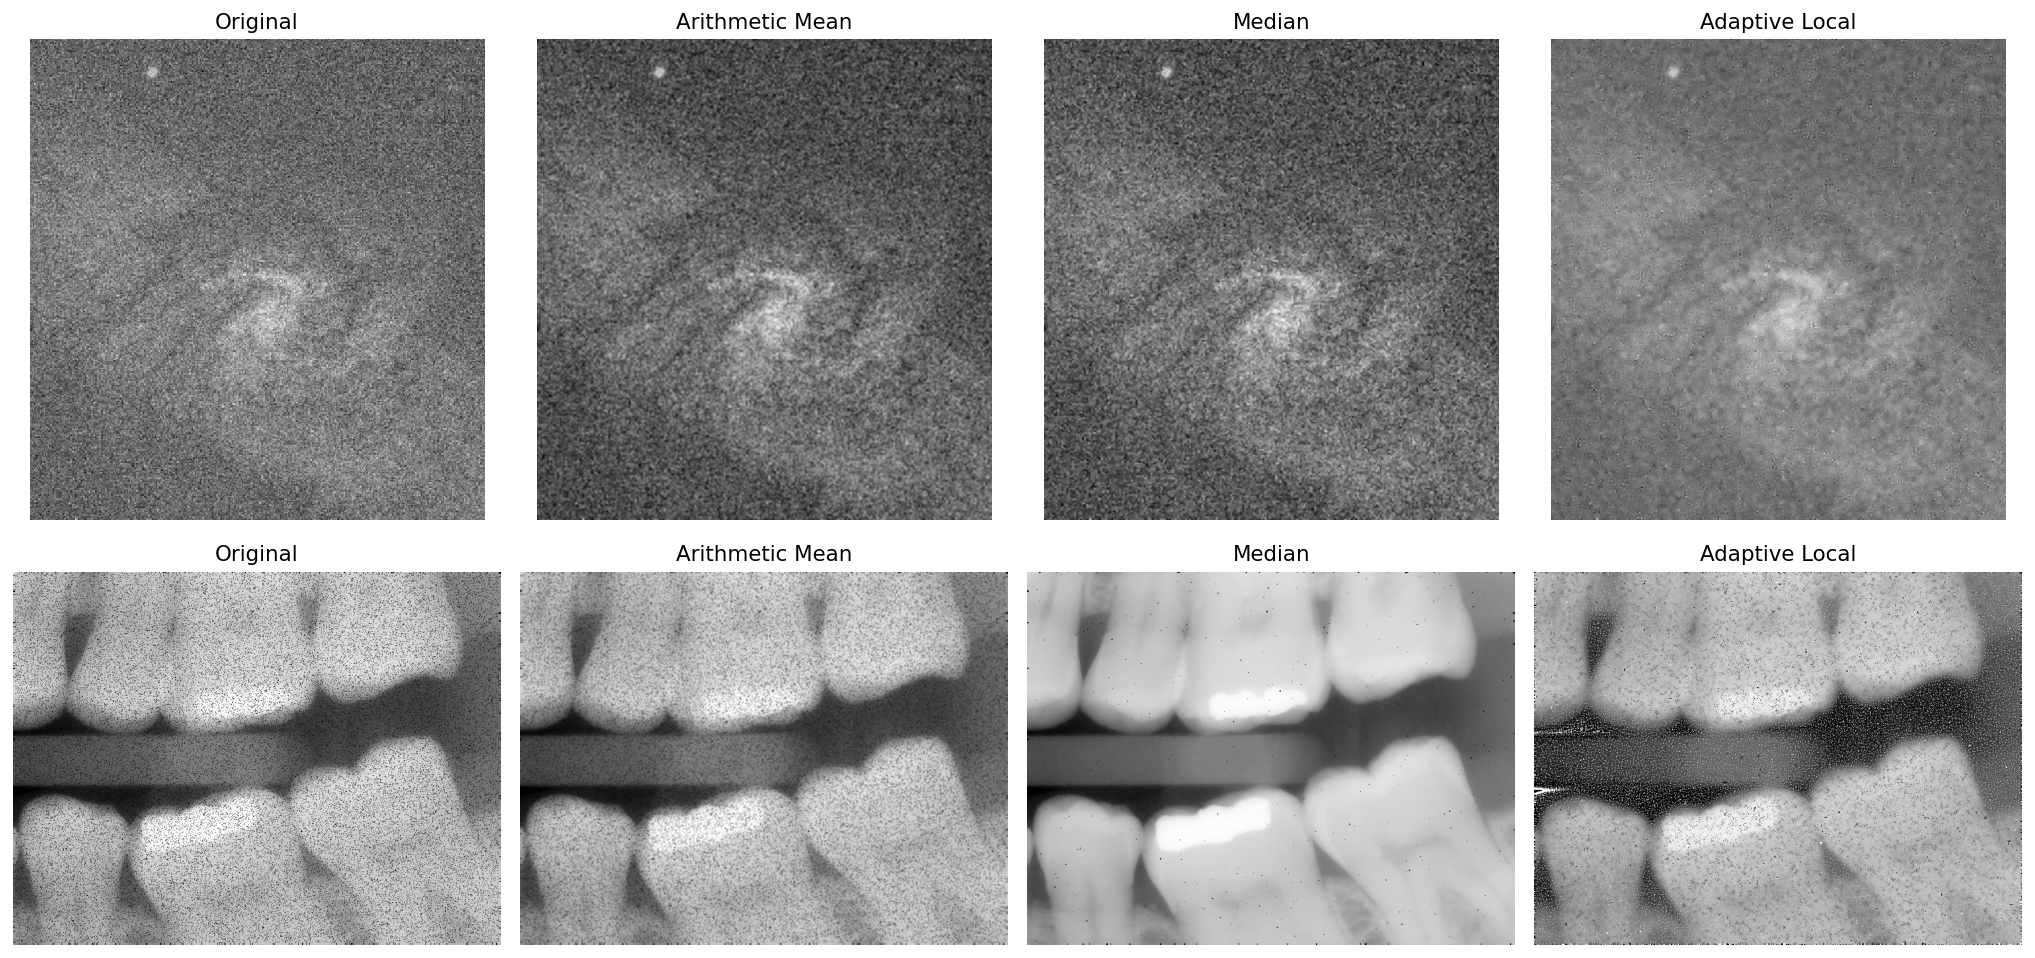

In [12]:


# 1. Arithmetic Mean Filter
def arithmetic_mean(img):
    return ndimage.uniform_filter(img.astype(float), size=3)

# 2. Median Filter
def median(img):
    return ndimage.median_filter(img, size=3)

# 3. Adaptive Local Noise Reduction
def adaptive_local_noise_reduction(img, size=7):
    img = img.astype(float)

    local_mean = ndimage.uniform_filter(img, size=size)
    local_mean_sq = ndimage.uniform_filter(img**2, size=size)
    local_var = np.maximum(local_mean_sq - local_mean**2, 0)

    # 잡음 분산 추정
    noise_var = np.mean(local_var)

    result = img - (noise_var / (local_var + 1e-10)) * (img - local_mean)

    return np.clip(result, 0, 255)


# 필터링 결과 계산
images = [f1, f2]
titles = ['Original', 'Arithmetic Mean', 'Median', 'Adaptive Local']

results = [
    [f1, arithmetic_mean(f1), median(f1),
     adaptive_local_noise_reduction(f1)],
    [f2, arithmetic_mean(f2), median(f2),
     adaptive_local_noise_reduction(f2)]
]

# 시각화: 2행 x 4열
fig, axes = plt.subplots(2, 4, figsize=(16, 8), dpi=128)

for i in range(2):
    for j in range(4):
        axes[i, j].imshow(results[i][j], cmap='gray')
        axes[i, j].set_title(titles[j])
        axes[i, j].axis('off')

axes[0, 0].set_ylabel('Galaxy', fontsize=12)
axes[1, 0].set_ylabel('Dental X-ray', fontsize=12)

plt.tight_layout()
plt.show()